In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

### Load the dataset and Understanding it

In [2]:
df = pd.read_excel(r"C:\Users\902pu\credit-risk-prediction\data\default of credit card clients.xls", header=1)

print("Shape:", df.shape)
df.head()

Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [23]:
df.columns.to_list()

['ID',
 'LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default']

In [22]:
df = df.rename(columns={
    "default payment next month": "default"
})

In [6]:
column_groups = {
    "Demographic": [
        "ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"
    ],
    
    "Repayment History": [
        "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"
    ],
    
    "Bill Amounts": [
        "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
        "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"
    ],
    
    "Previous Payments": [
        "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
        "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
    ]
}

for group, columns in column_groups.items():
    print(f"\n{group}")
    print(columns)


Demographic
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE']

Repayment History
['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

Bill Amounts
['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']

Previous Payments
['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [7]:
for col in ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
    print(f"\n{col}")
    print(sorted(df[col].unique()))


PAY_0
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_2
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_3
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_4
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_5
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

PAY_6
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [24]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


Target distribution

In [25]:
print(
    df["default"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

default
0    77.88
1    22.12
Name: proportion, dtype: float64


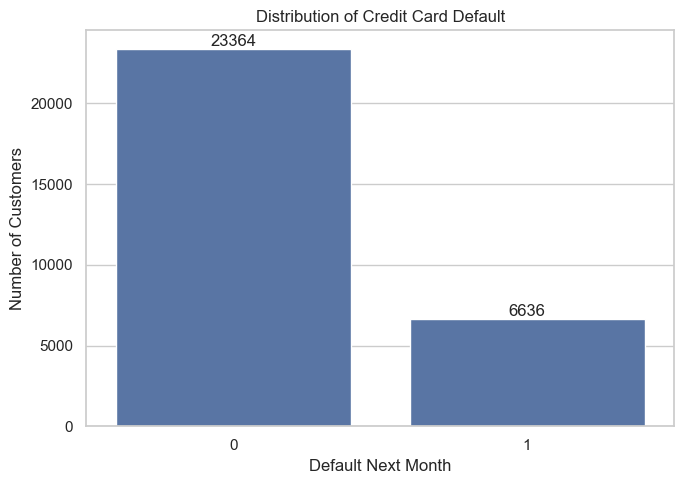

In [26]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="default")

plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Next Month")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

Age Distibution

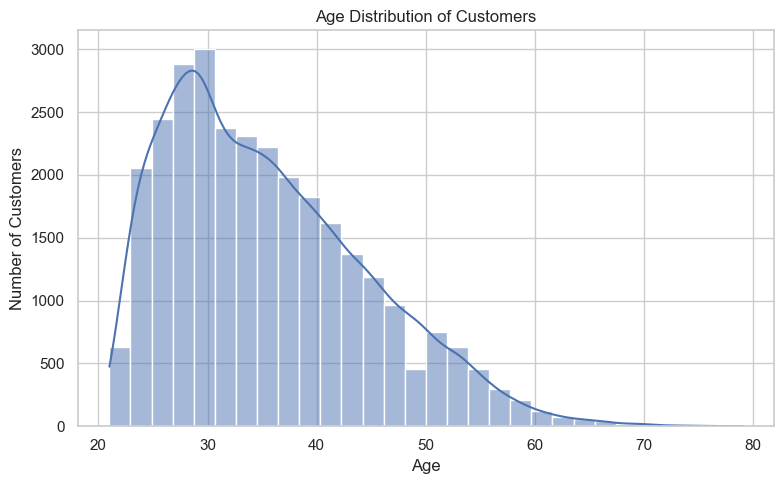

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="AGE",
    bins=30,
    kde=True
)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Credit limit distribution 

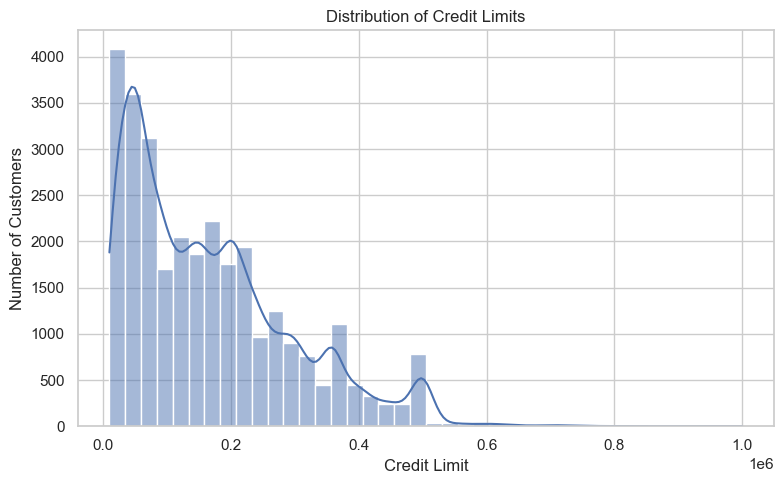

In [29]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="LIMIT_BAL",
    bins=40,
    kde=True
)

plt.title("Distribution of Credit Limits")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Credit limit vs default

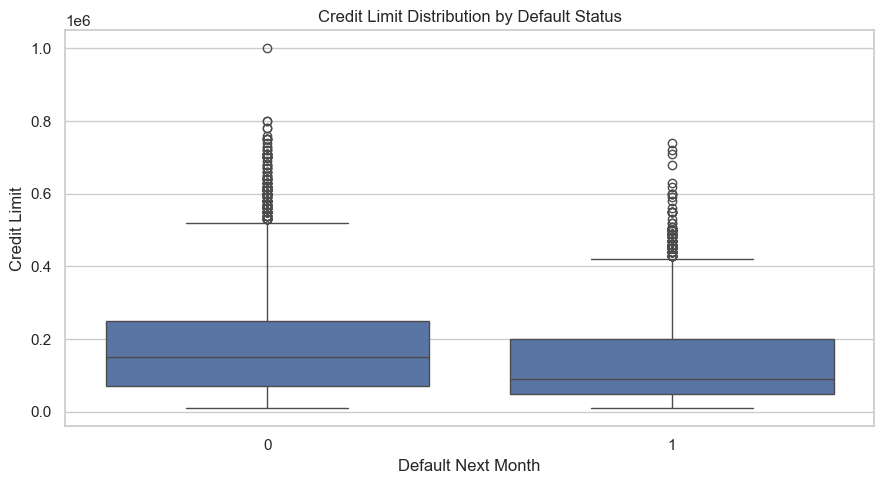

In [30]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="default",
    y="LIMIT_BAL"
)

plt.title("Credit Limit Distribution by Default Status")
plt.xlabel("Default Next Month")
plt.ylabel("Credit Limit")

plt.tight_layout()
plt.show()

Investigate outliers

In [31]:
numeric_columns = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

In [32]:
outlier_summary = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    
    outlier_summary.append({
        "column": col,
        "Q1": Q1,
        "Q3": Q3,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": count,
        "outlier_percentage": count / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    "outlier_percentage",
    ascending=False
)

,column,Q1,Q3,lower_bound,upper_bound,outlier_count,outlier_percentage
11,PAY_AMT4,296.00,4013.25,-5279.875,9589.125,2994,9.980000
13,PAY_AMT6,117.75,4000.00,-5705.625,9823.375,2958,9.860000
12,PAY_AMT5,252.50,4031.50,-5416.000,9700.000,2945,9.816667
8,PAY_AMT1,1000.00,5006.00,-5009.000,11015.000,2745,9.150000
6,BILL_AMT5,1763.00,50190.50,-70878.250,122831.750,2725,9.083333
9,PAY_AMT2,833.00,5000.00,-5417.500,11250.500,2714,9.046667
7,BILL_AMT6,1256.00,49198.25,-70657.375,121111.625,2693,8.976667
5,BILL_AMT4,2326.75,54506.00,-75942.125,132774.875,2622,8.740000
10,PAY_AMT3,390.00,4505.00,-5782.500,10677.500,2598,8.660000
4,BILL_AMT3,2666.25,60164.75,-83581.500,146412.500,2469,8.230000


Check  categorical values

In [33]:
categorical_columns = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

for col in categorical_columns:
    print(f"\n===== {col} =====")
    print(df[col].value_counts().sort_index())


===== SEX =====
SEX
1    11888
2    18112
Name: count, dtype: int64

===== EDUCATION =====
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

===== MARRIAGE =====
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


Investigate repayment behavior

In [34]:
payment_columns = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

for col in payment_columns:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


PAY_0
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

PAY_4
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

PAY_5
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64

PAY_6
PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2
Name: count, dtype: int6

In [ ]:
for col in payment_columns:
    result = (
        df.groupby(col)["default"]
          .mean()
          .mul(100)
          .round(2)
    )
    
    print(f"\nDefault rate by {col}")
    print(result)

Correlation Analysis

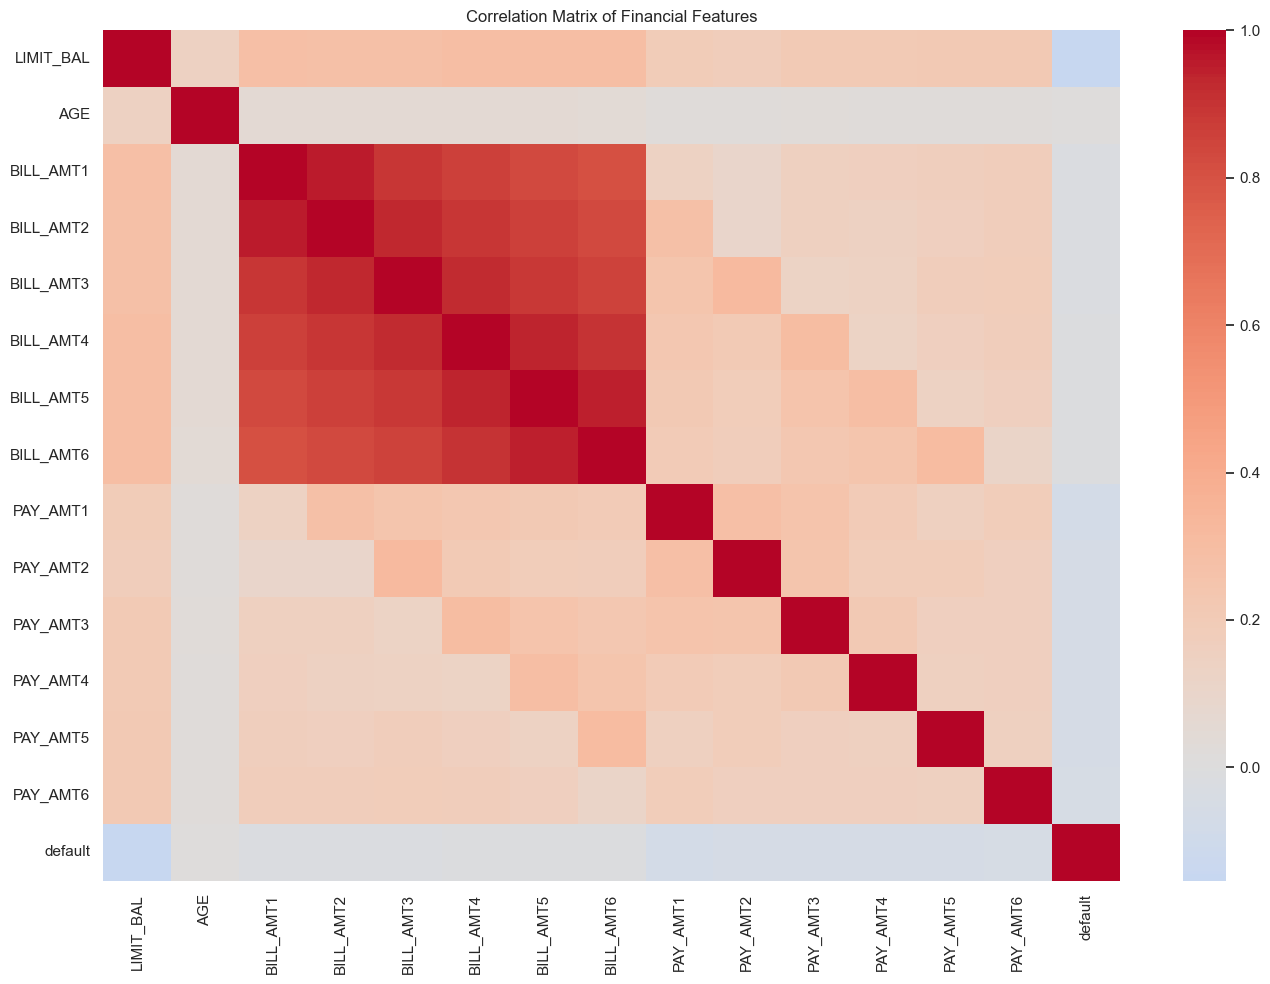

In [35]:
plt.figure(figsize=(14, 10))

correlation = df[
    numeric_columns + ["default"]
].corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Financial Features")

plt.tight_layout()
plt.show()

In [38]:
df_model = df.drop(columns=["AGE"]).copy()

In [39]:
df_model.to_csv(
    "data/credit_risk_cleaned.csv",
    index=False
)

In [40]:
df.shape

(30000, 25)

In [41]:
df.isnull().sum()

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
default      0
dtype: int64

In [42]:
df['default'].value_counts()

default
0    23364
1     6636
Name: count, dtype: int64

In [43]:
df["default"].value_counts()

default
0    23364
1     6636
Name: count, dtype: int64

In [44]:
df["EDUCATION"].value_counts().sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

In [45]:
df["MARRIAGE"].value_counts().sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

check duplicates and unusual values

In [46]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())

print("\nSEX values:")
print(df["SEX"].value_counts().sort_index())

print("\nEDUCATION values:")
print(df["EDUCATION"].value_counts().sort_index())

print("\nMARRIAGE values:")
print(df["MARRIAGE"].value_counts().sort_index())

print("\nAGE range:")
print(df["AGE"].min(), "to", df["AGE"].max())

print("\nLIMIT_BAL range:")
print(df["LIMIT_BAL"].min(), "to", df["LIMIT_BAL"].max())

Duplicate rows: 0
Duplicate IDs: 0

SEX values:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION values:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE values:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

AGE range:
21 to 79

LIMIT_BAL range:
10000 to 1000000


In [47]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

for col in pay_cols:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


PAY_0
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

PAY_4
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

PAY_5
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64

PAY_6
PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2
Name: count, dtype: int6

In [48]:
pay_default_rate = df.groupby("PAY_0")["default"].mean() * 100

print(pay_default_rate.round(2))

PAY_0
-2    13.23
-1    16.78
 0    12.81
 1    33.95
 2    69.14
 3    75.78
 4    68.42
 5    50.00
 6    54.55
 7    77.78
 8    57.89
Name: default, dtype: float64


In [49]:
education_default_rate = df.groupby("EDUCATION")["default"].mean() * 100

print(education_default_rate.round(2))

EDUCATION
0     0.00
1    19.23
2    23.73
3    25.16
4     5.69
5     6.43
6    15.69
Name: default, dtype: float64


Feature Enginerring

In [50]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

bill_cols = [
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"
]

payment_cols = [
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

df["avg_pay_status"] = df[pay_cols].mean(axis=1)

df["num_delays"] = (df[pay_cols] >= 2).sum(axis=1)

df["avg_bill_amount"] = df[bill_cols].mean(axis=1)

df["avg_payment_amount"] = df[payment_cols].mean(axis=1)

df["credit_utilization"] = (
    df["avg_bill_amount"] / df["LIMIT_BAL"]
)

df["payment_ratio"] = (
    df["avg_payment_amount"] /
    (df["avg_bill_amount"].abs() + 1)
)

df[
    [
        "avg_pay_status",
        "num_delays",
        "avg_bill_amount",
        "avg_payment_amount",
        "credit_utilization",
        "payment_ratio"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_pay_status,30000.0,-0.182439,0.982176,-2.000000,-0.833333,0.000000,0.000000,6.000000
num_delays,30000.0,0.710133,1.464712,0.000000,0.000000,0.000000,1.000000,6.000000
avg_bill_amount,30000.0,44976.945200,63260.721860,-56043.166667,4781.333333,21051.833333,57104.416667,877313.833333
avg_payment_amount,30000.0,5275.232094,10137.946323,0.000000,1113.291667,2397.166667,5583.916667,627344.333333
credit_utilization,30000.0,0.373048,0.351890,-0.232590,0.029997,0.284834,0.687929,5.364308
payment_ratio,30000.0,3.984841,209.398071,0.000000,0.041302,0.087862,0.608411,27000.000000


### Prepare data for ML

In [51]:
# Remove ID
df_model = df.drop(columns=["ID"]).copy()

print(df_model.shape)
print(df_model.head())

(30000, 30)
   LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0      20000    2          2         1   24      2      2     -1     -1   
1     120000    2          2         2   26     -1      2      0      0   
2      90000    2          2         2   34      0      0      0      0   
3      50000    2          2         1   37      0      0      0      0   
4      50000    1          2         1   57     -1      0     -1      0   

   PAY_5  PAY_6  BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  BILL_AMT5  \
0     -2     -2       3913       3102        689          0          0   
1      0      2       2682       1725       2682       3272       3455   
2      0      0      29239      14027      13559      14331      14948   
3      0      0      46990      48233      49291      28314      28959   
4      0      0       8617       5670      35835      20940      19146   

   BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  PAY_AMT4  PAY_AMT5  PAY_AMT6  \
0          0    

In [52]:
X = df_model.drop(columns=["default"])
y = df_model["default"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30000, 29)
y shape: (30000,)


Train/Test Split

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (24000, 29)
Testing: (6000, 29)


In [54]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Train Logistic Regression

In [55]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


Prediction 

In [56]:
y_pred = log_model.predict(X_test_scaled)

y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

Evaluate the baseline

In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))
print("PR-AUC   :", average_precision_score(y_test, y_prob))

Accuracy : 0.8085
Precision: 0.6529209621993127
Recall   : 0.2863602110022607
F1 Score : 0.39811419591409114
ROC-AUC  : 0.7471236823445498
PR-AUC   : 0.519903630287855


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

Random Forest

In [58]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [59]:
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [60]:
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))
print("ROC-AUC  :", roc_auc_score(y_test, rf_prob))
print("PR-AUC   :", average_precision_score(y_test, rf_prob))

Accuracy : 0.8165
Precision: 0.660056657223796
Recall   : 0.35116804822908815
F1 Score : 0.4584358091490408
ROC-AUC  : 0.7789060147835752
PR-AUC   : 0.5581769756812424


In [ ]:
print(confusion_matrix(y_test, rf_pred))

Train XGBoost

In [62]:
import sys
!{sys.executable} -m pip install xgboost


  Using cached xgboost-3.2.0-py3-none-win_amd64.whl.metadata (2.1 kB)
Using cached xgboost-3.2.0-py3-none-win_amd64.whl (101.7 MB)


In [63]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [64]:
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

In [65]:
print("Accuracy :", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall   :", recall_score(y_test, xgb_pred))
print("F1 Score :", f1_score(y_test, xgb_pred))
print("ROC-AUC  :", roc_auc_score(y_test, xgb_prob))
print("PR-AUC   :", average_precision_score(y_test, xgb_prob))

Accuracy : 0.8203333333333334
Precision: 0.6707818930041153
Recall   : 0.36850037678975134
F1 Score : 0.47568093385214005
ROC-AUC  : 0.780639505659587
PR-AUC   : 0.5640612203640336


In [ ]:
print(confusion_matrix(y_test, xgb_pred))

In [66]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:
    pred = (xgb_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_test, pred):.3f} | "
        f"Recall: {recall_score(y_test, pred):.3f} | "
        f"F1: {f1_score(y_test, pred):.3f}"
    )

Threshold: 0.20 | Precision: 0.431 | Recall: 0.669 | F1: 0.525
Threshold: 0.25 | Precision: 0.492 | Recall: 0.603 | F1: 0.542
Threshold: 0.30 | Precision: 0.534 | Recall: 0.550 | F1: 0.542
Threshold: 0.35 | Precision: 0.574 | Recall: 0.501 | F1: 0.535
Threshold: 0.40 | Precision: 0.609 | Recall: 0.445 | F1: 0.514
Threshold: 0.45 | Precision: 0.642 | Recall: 0.404 | F1: 0.496
Threshold: 0.50 | Precision: 0.671 | Recall: 0.369 | F1: 0.476


In [67]:
feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(feature_importance.head(15))

num_delays            0.312043
PAY_0                 0.293458
avg_pay_status        0.037606
avg_bill_amount       0.021535
avg_payment_amount    0.019228
PAY_2                 0.018185
payment_ratio         0.016718
LIMIT_BAL             0.016637
PAY_AMT2              0.016506
credit_utilization    0.016329
BILL_AMT1             0.015837
PAY_3                 0.015550
PAY_4                 0.015059
PAY_AMT3              0.013047
PAY_AMT1              0.013045
dtype: float32


In [70]:
from sklearn.metrics import confusion_matrix

threshold = 0.25

xgb_pred_025 = (xgb_prob >= threshold).astype(int)

cm_025 = confusion_matrix(y_test, xgb_pred_025)

print(cm_025)

print("\nPrecision:", precision_score(y_test, xgb_pred_025))
print("Recall   :", recall_score(y_test, xgb_pred_025))
print("F1       :", f1_score(y_test, xgb_pred_025))

[[3846  827]
 [ 527  800]]

Precision: 0.49170251997541486
Recall   : 0.6028636021100227
F1       : 0.5416384563303994


In [71]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(xgb_model, "../models/xgb_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [72]:
os.makedirs("models", exist_ok=True)

joblib.dump(xgb_model, "models/xgb_model.pkl")

['models/xgb_model.pkl']

In [73]:
feature_names = list(X_train.columns)

joblib.dump(feature_names, "../models/feature_names.pkl")

print(feature_names)

['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'avg_pay_status', 'num_delays', 'avg_bill_amount', 'avg_payment_amount', 'credit_utilization', 'payment_ratio']


In [74]:
with open("../models/threshold.txt", "w") as f:
    f.write("0.25")

In [78]:
df_model.to_csv(
    "data/credit_risk_engineered.csv",
    index=False
)

In [79]:
threshold = 0.25

xgb_pred_025 = (xgb_prob >= threshold).astype(int)

print(confusion_matrix(y_test, xgb_pred_025))

print("Precision:", precision_score(y_test, xgb_pred_025))
print("Recall   :", recall_score(y_test, xgb_pred_025))
print("F1 Score :", f1_score(y_test, xgb_pred_025))

[[3846  827]
 [ 527  800]]
Precision: 0.49170251997541486
Recall   : 0.6028636021100227
F1 Score : 0.5416384563303994


save the trained model

In [80]:
import os
import joblib

os.makedirs("models", exist_ok=True)

# Save trained XGBoost model
joblib.dump(xgb_model, "models/xgb_model.pkl")

# Save feature names
feature_names = list(X_train.columns)
joblib.dump(feature_names, "models/feature_names.pkl")

# Save selected threshold
with open("models/threshold.txt", "w") as f:
    f.write("0.25")

# Save engineered dataset
df_model.to_csv("data/credit_risk_engineered.csv", index=False)

print("Model and project files saved successfully.")

Model and project files saved successfully.


In [81]:
import os

print(os.listdir("models"))

['feature_names.pkl', 'threshold.txt', 'xgb_model.pkl']
